# Household Electricity Consumption Analysis

**Roll number:** 2026B01010250  |  **Domain:** Electricity consumption  |  **Data:** synthetic (computer-generated) practice data

## 1. Business problem
A state electricity distribution company wants to know why some households use much more electricity than others. The planning team needs this to forecast demand and to find high-usage homes for energy-saving campaigns and better tariff offers. My job is to find out which factors push the monthly units (kWh) up and which homes need attention.

## The four questions
1. What does `Monthly_Units_kWh` look like overall?
2. Do `Home_Area_Sqft` and `Num_Air_Conditioners` affect `Monthly_Units_kWh`?
3. Does `Monthly_Units_kWh` differ by `City`, `Housing_Type` and `Tariff_Plan`?
4. Which households need attention? (I define a **High Consumer** as a household using **more than 300 kWh in a month**.)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(10250)   # last 6 digits of my roll number

os.makedirs("../images", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

# simple, readable chart style
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "figure.dpi": 110,
})
pd.set_option("display.max_columns", None)

## 2. Load and inspect the data
First I load the raw file exactly as it was given to me and look at it before changing anything.

In [2]:
df = pd.read_csv("../data/raw/electricity_data.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (255, 11)


,Household_ID,City,Housing_Type,Tariff_Plan,Household_Size,Home_Area_Sqft,Num_Air_Conditioners,Avg_Temperature_C,Meter_Age_Years,Billing_Date,Monthly_Units_kWh
0,E1139,Mumbai,Independent House,Standard,4,1320.0,2,30.7,1.0,2025-07-22,211
1,E1119,Delhi,Apartment,Standard,4,1230.0,2,35.4,4.0,2025-05-05,232
2,E1007,Delhi,Apartment,Time_of_Day,3,870.0,2,36.4,9.0,2026-06-17,182
3,E1184,Mumbai,Apartment,Solar_Net_Metering,4,950.0,1,27.1,5.0,2025-03-05,209
4,E1089,Delhi,Apartment,Standard,2,900.0,1,25.4,0.0,2026-08-23,183


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Household_ID          255 non-null    str    
 1   City                  255 non-null    str    
 2   Housing_Type          249 non-null    str    
 3   Tariff_Plan           255 non-null    str    
 4   Household_Size        255 non-null    int64  
 5   Home_Area_Sqft        250 non-null    float64
 6   Num_Air_Conditioners  255 non-null    int64  
 7   Avg_Temperature_C     251 non-null    float64
 8   Meter_Age_Years       250 non-null    float64
 9   Billing_Date          255 non-null    str    
 10  Monthly_Units_kWh     255 non-null    int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 22.0 KB


In [4]:
df.describe()

,Household_Size,Home_Area_Sqft,Num_Air_Conditioners,Avg_Temperature_C,Meter_Age_Years,Monthly_Units_kWh
count,255.000000,250.000000,255.000000,251.000000,250.00000,255.000000
mean,3.831373,1194.160000,1.521569,26.745020,4.90000,215.501961
std,1.528919,575.553771,0.904127,5.271638,3.19041,78.046971
min,-3.000000,400.000000,0.000000,11.500000,0.00000,40.000000
25%,3.000000,782.500000,1.000000,23.500000,2.00000,163.000000
50%,4.000000,1030.000000,1.000000,26.800000,5.00000,216.000000
75%,5.000000,1562.500000,2.000000,30.900000,8.00000,267.000000
max,8.000000,3320.000000,4.000000,37.500000,10.00000,444.000000


In [5]:
print("Missing values per column:")
print(df.isna().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print()
for col in ["City", "Housing_Type", "Tariff_Plan"]:
    print(col, "->", df[col].value_counts(dropna=False).to_dict())
print()
print("Household_Size values below 1:", (df["Household_Size"] < 1).sum())

Missing values per column:
Household_ID            0
City                    0
Housing_Type            6
Tariff_Plan             0
Household_Size          0
Home_Area_Sqft          5
Num_Air_Conditioners    0
Avg_Temperature_C       4
Meter_Age_Years         5
Billing_Date            0
Monthly_Units_kWh       0
dtype: int64

Duplicate rows: 5

City -> {'Delhi': 71, 'Bengaluru': 56, 'Mumbai': 53, 'Chennai': 34, 'Kolkata': 34, ' Chennai ': 2, ' Delhi ': 2, 'delhi': 1, 'mumbai': 1, 'DELHI': 1}
Housing_Type -> {'Apartment': 142, 'Independent House': 77, 'Villa': 30, nan: 6}
Tariff_Plan -> {'Standard': 158, 'Time_of_Day': 72, 'Solar_Net_Metering': 25}

Household_Size values below 1: 2


### What I found while inspecting
- **Shape:** 255 rows and 11 columns, but the ID column should only have 250 unique households.
- **Duplicates:** 5 rows are exact copies of other rows.
- **Missing values:** four columns have a few empty cells (`Housing_Type`, `Home_Area_Sqft`, `Avg_Temperature_C`, `Meter_Age_Years`).
- **Inconsistent text:** `City` has the same city written in different ways (for example different capital letters and extra spaces), so one city shows up as several different values.
- **Impossible values:** `Household_Size` has negative numbers, and a household cannot have fewer than 1 person.

## 3. Clean the data
I clean in a fixed order: duplicates first (so they do not affect any averages), then text, then impossible values, then missing values.

In [6]:
rows_before = len(df)

# 1) Duplicates: an exact copy is the same household counted twice, so I drop the copies.
print("Duplicate rows removed:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# 2) Inconsistent text: remove extra spaces and make the capital letters the same.
print("City values before:", sorted(df["City"].unique()))
for col in ["City", "Housing_Type", "Tariff_Plan"]:
    df[col] = df[col].str.strip()
df["City"] = df["City"].str.title()
print("City values after: ", sorted(df["City"].unique()))

Duplicate rows removed: 5
City values before: [' Chennai ', ' Delhi ', 'Bengaluru', 'Chennai', 'DELHI', 'Delhi', 'Kolkata', 'Mumbai', 'delhi', 'mumbai']
City values after:  ['Bengaluru', 'Chennai', 'Delhi', 'Kolkata', 'Mumbai']


In [7]:
# 3) Impossible values: a negative household size cannot be true.
#    I treat them as missing (NaN) and fill them together with the other missing values.
bad_size = df["Household_Size"] < 1
print(df.loc[bad_size, ["Household_ID", "Household_Size"]])
df.loc[bad_size, "Household_Size"] = np.nan

    Household_ID  Household_Size
130        E1025              -3
161        E1245              -1


In [8]:
# 4) Missing values
print("Missing before:")
print(df.isna().sum()[df.isna().sum() > 0])

# Housing_Type is a category, so I use the most common value (mode).
df["Housing_Type"] = df["Housing_Type"].fillna(df["Housing_Type"].mode()[0])

# Area depends on the housing type (villas are bigger than apartments), so I use the median of the same type.
df["Home_Area_Sqft"] = df["Home_Area_Sqft"].fillna(df.groupby("Housing_Type")["Home_Area_Sqft"].transform("median"))

# Temperature depends on the city, so I use the median temperature of the same city.
df["Avg_Temperature_C"] = df["Avg_Temperature_C"].fillna(df.groupby("City")["Avg_Temperature_C"].transform("median"))

# Meter age and household size: the overall median (it is not pulled by extreme values).
df["Meter_Age_Years"] = df["Meter_Age_Years"].fillna(df["Meter_Age_Years"].median())
df["Household_Size"] = df["Household_Size"].fillna(df["Household_Size"].median())

# Fix the data types again after filling
for col in ["Household_Size", "Home_Area_Sqft", "Meter_Age_Years"]:
    df[col] = df[col].round().astype(int)
df["Avg_Temperature_C"] = df["Avg_Temperature_C"].round(1)
df["Billing_Date"] = pd.to_datetime(df["Billing_Date"])

print()
print("Missing after:", int(df.isna().sum().sum()))
print("Rows before / after cleaning:", rows_before, "/", len(df))
print("Unique Household_ID:", df["Household_ID"].nunique())

Missing before:
Housing_Type         6
Household_Size       2
Home_Area_Sqft       5
Avg_Temperature_C    4
Meter_Age_Years      5
dtype: int64

Missing after: 0
Rows before / after cleaning: 255 / 250
Unique Household_ID: 250


### Why I fixed it this way
- **Duplicates were dropped**, not kept, because the same household must be counted only once. After this I have 250 unique households.
- **Text** was made consistent so that "delhi", "DELHI" and " Delhi " are all counted as one city.
- **Negative household sizes** cannot be real, so I changed them to missing and filled them with the median instead of deleting the rows (the other columns of those rows are still useful).
- **Missing values** were filled with the median of a similar group (same housing type or same city) when a sensible group exists. Group medians keep the data realistic and do not hide the real patterns. I did not fill the outcome column because it had no missing values.

## 4. Create new columns
I create five new columns to help the analysis.

In [9]:
# 1) Combine two columns: how many units per square foot
df["Units_Per_Sqft"] = (df["Monthly_Units_kWh"] / df["Home_Area_Sqft"]).round(3)

# 2) Labels with conditions
df["Consumption_Level"] = np.select(
    [df["Monthly_Units_kWh"] <= 150, df["Monthly_Units_kWh"] <= 300],
    ["Low", "Medium"], default="High")
df["High_Consumer"] = np.where(df["Monthly_Units_kWh"] > 300, "Yes", "No")

# 3) Bin a numeric column: size band for the home
df["Area_Band"] = pd.cut(df["Home_Area_Sqft"], bins=[0, 800, 1500, 4000],
                         labels=["Small (up to 800)", "Medium (801-1500)", "Large (above 1500)"]).astype(str)

# 4) Estimated bill, assuming a flat Rs 7 per unit (my own simple assumption)
df["Estimated_Bill_Rs"] = (df["Monthly_Units_kWh"] * 7).round().astype(int)

# 5) Month number from the date
df["Billing_Month"] = df["Billing_Date"].dt.month

df[["Household_ID", "Monthly_Units_kWh", "Units_Per_Sqft", "Consumption_Level",
    "High_Consumer", "Area_Band", "Estimated_Bill_Rs", "Billing_Month"]].head()

,Household_ID,Monthly_Units_kWh,Units_Per_Sqft,Consumption_Level,High_Consumer,Area_Band,Estimated_Bill_Rs,Billing_Month
0,E1139,211,0.160,Medium,No,Medium (801-1500),1477,7
1,E1119,232,0.189,Medium,No,Medium (801-1500),1624,5
2,E1007,182,0.209,Medium,No,Medium (801-1500),1274,6
3,E1184,209,0.220,Medium,No,Medium (801-1500),1463,3
4,E1089,183,0.203,Medium,No,Medium (801-1500),1281,8


- `Units_Per_Sqft` = units divided by area (usage relative to home size)
- `Consumption_Level` = Low (up to 150 kWh), Medium (151 to 300 kWh), High (above 300 kWh)
- `High_Consumer` = Yes if units are above 300 kWh (used for Question 4)
- `Area_Band` = Small, Medium or Large home, made by binning `Home_Area_Sqft`
- `Estimated_Bill_Rs` = units x Rs 7 (assumed flat rate, only for a rough idea of the bill)
- `Billing_Month` = month number taken from `Billing_Date`

## 5. Question 1: What does the outcome look like overall?

In [10]:
units = df["Monthly_Units_kWh"]
summary = units.describe().round(1)
summary["skewness"] = round(units.skew(), 2)
summary

count       250.00
mean        214.50
std          78.00
min          40.00
25%         161.20
50%         215.00
75%         266.80
max         444.00
skewness      0.03
Name: Monthly_Units_kWh, dtype: float64

/tmp/ipykernel_341/4226878515.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(units, vert=True, widths=0.5, patch_artist=True,


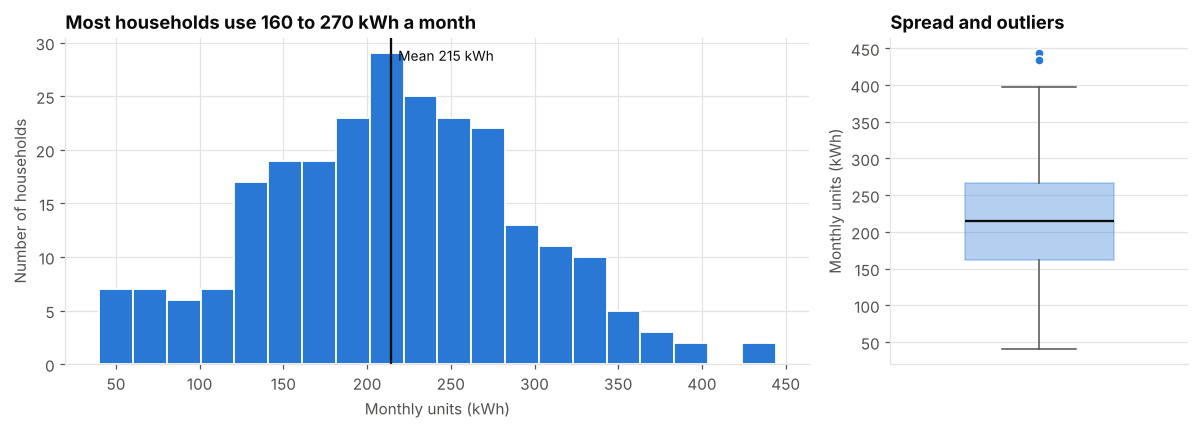

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [3, 1.2]})

ax[0].hist(units, bins=20, color=BLUE, edgecolor="white", linewidth=1.2)
ax[0].axvline(units.mean(), color=INK, linewidth=1.5)
ax[0].text(units.mean() + 4, ax[0].get_ylim()[1] * 0.93, f"Mean {units.mean():.0f} kWh", color=INK, fontsize=9)
ax[0].set_title("Most households use 160 to 270 kWh a month")
ax[0].set_xlabel("Monthly units (kWh)")
ax[0].set_ylabel("Number of households")

ax[1].boxplot(units, vert=True, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor=BLUE, alpha=0.35, edgecolor=BLUE),
              medianprops=dict(color=INK, linewidth=1.5),
              whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
              flierprops=dict(marker="o", markerfacecolor=BLUE, markeredgecolor="white", markersize=6))
ax[1].set_title("Spread and outliers")
ax[1].set_xticks([])
ax[1].set_ylabel("Monthly units (kWh)")
plt.tight_layout()
plt.savefig("../images/01_units_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**What I see:** the usage is roughly bell-shaped with a small tail of heavy users on the right. The mean and median are close, so there is no very strong skew. The boxplot shows a few households far above the rest.

## 6. Question 2: Do area and number of ACs affect the outcome?

In [12]:
num_cols = ["Household_Size", "Home_Area_Sqft", "Num_Air_Conditioners", "Avg_Temperature_C", "Meter_Age_Years"]
corr_table = df[num_cols + ["Monthly_Units_kWh"]].corr()["Monthly_Units_kWh"].drop("Monthly_Units_kWh").sort_values(ascending=False).round(2)
corr_table.to_frame("Correlation with Monthly_Units_kWh")

,Correlation with Monthly_Units_kWh
Num_Air_Conditioners,0.57
Home_Area_Sqft,0.41
Household_Size,0.15
Meter_Age_Years,0.08
Avg_Temperature_C,0.06


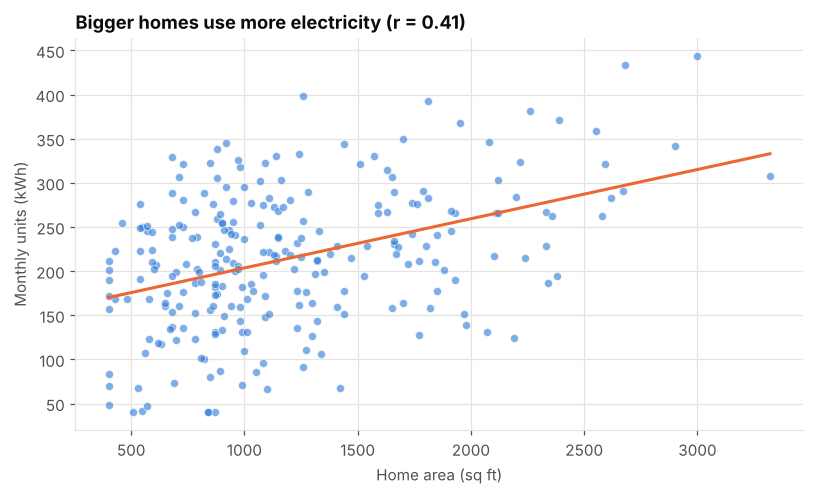

In [13]:
r_area = df["Home_Area_Sqft"].corr(df["Monthly_Units_kWh"])

fig, ax = plt.subplots(figsize=(7.5, 4.6))
sns.regplot(data=df, x="Home_Area_Sqft", y="Monthly_Units_kWh", ax=ax,
            scatter_kws=dict(alpha=0.6, s=28, color=BLUE, edgecolor="white", linewidths=0.6),
            line_kws=dict(color=ORANGE, linewidth=2), ci=None)
ax.set_title(f"Bigger homes use more electricity (r = {r_area:.2f})")
ax.set_xlabel("Home area (sq ft)")
ax.set_ylabel("Monthly units (kWh)")
plt.tight_layout()
plt.savefig("../images/02_area_vs_units.png", dpi=150, bbox_inches="tight")
plt.show()

                      count   mean  median
Num_Air_Conditioners                      
0                        30  146.3   134.5
1                        95  186.6   185.0
2                        92  234.7   234.5
3                        29  297.5   291.0
4                         4  323.2   316.0


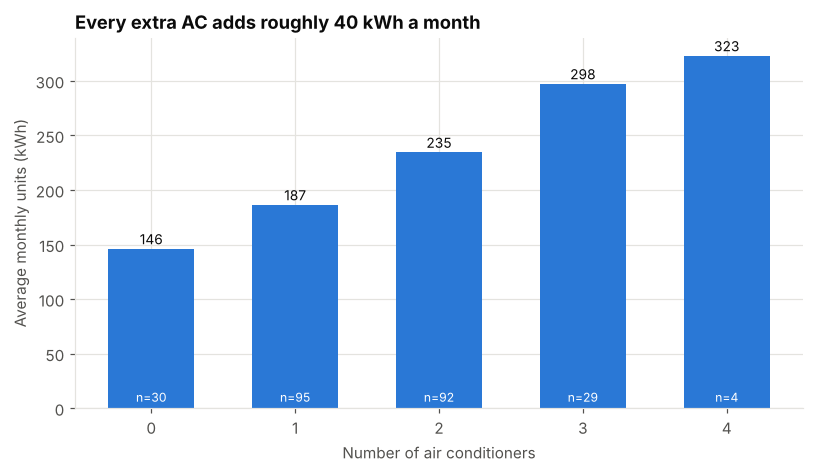

In [14]:
ac_table = df.groupby("Num_Air_Conditioners")["Monthly_Units_kWh"].agg(["count", "mean", "median"]).round(1)
print(ac_table)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
bars = ax.bar(ac_table.index.astype(str), ac_table["mean"], color=BLUE, width=0.6)
for b, (n, m) in zip(bars, zip(ac_table["count"], ac_table["mean"])):
    ax.text(b.get_x() + b.get_width() / 2, m + 4, f"{m:.0f}", ha="center", color=INK, fontsize=9)
    ax.text(b.get_x() + b.get_width() / 2, 6, f"n={n}", ha="center", color="white", fontsize=8)
ax.set_title("Every extra AC adds roughly 40 kWh a month")
ax.set_xlabel("Number of air conditioners")
ax.set_ylabel("Average monthly units (kWh)")
plt.tight_layout()
plt.savefig("../images/03_acs_vs_units.png", dpi=150, bbox_inches="tight")
plt.show()

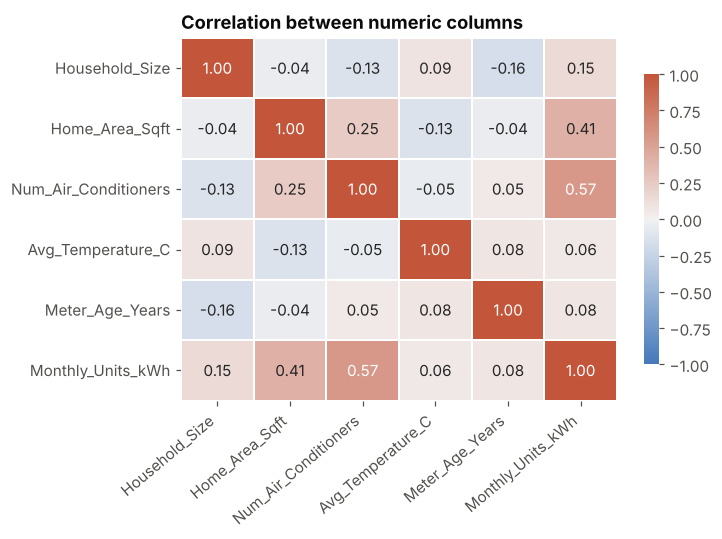

In [15]:
fig, ax = plt.subplots(figsize=(6.8, 5))
cm = df[num_cols + ["Monthly_Units_kWh"]].corr()
sns.heatmap(cm, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 20, as_cmap=True, center="light"),
            vmin=-1, vmax=1, linewidths=1, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation between numeric columns")
ax.grid(False)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("../images/04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**What I see:** both `Home_Area_Sqft` and `Num_Air_Conditioners` have a clear positive relationship with units. ACs have the stronger one. `Household_Size` and `Avg_Temperature_C` have weak positive links, and `Meter_Age_Years` has almost no relationship with units, which makes sense because the age of a meter should not change how much power a home uses.

## 7. Question 3: Does the outcome differ by City, Housing Type and Tariff Plan?

In [16]:
for col in ["City", "Housing_Type", "Tariff_Plan"]:
    t = df.groupby(col)["Monthly_Units_kWh"].agg(["count", "mean", "median"]).round(1).sort_values("mean", ascending=False)
    print(t, "\n")

           count   mean  median
City                           
Chennai       36  238.7   232.0
Mumbai        53  224.1   223.0
Bengaluru     54  216.2   215.5
Delhi         73  213.5   217.0
Kolkata       34  173.5   181.0 

                   count   mean  median
Housing_Type                           
Villa                 29  278.0   266.0
Independent House     76  223.2   222.5
Apartment            145  197.3   203.0 

                    count   mean  median
Tariff_Plan                             
Standard              155  221.0   221.0
Time_of_Day            70  214.4   215.0
Solar_Net_Metering     25  174.8   160.0 



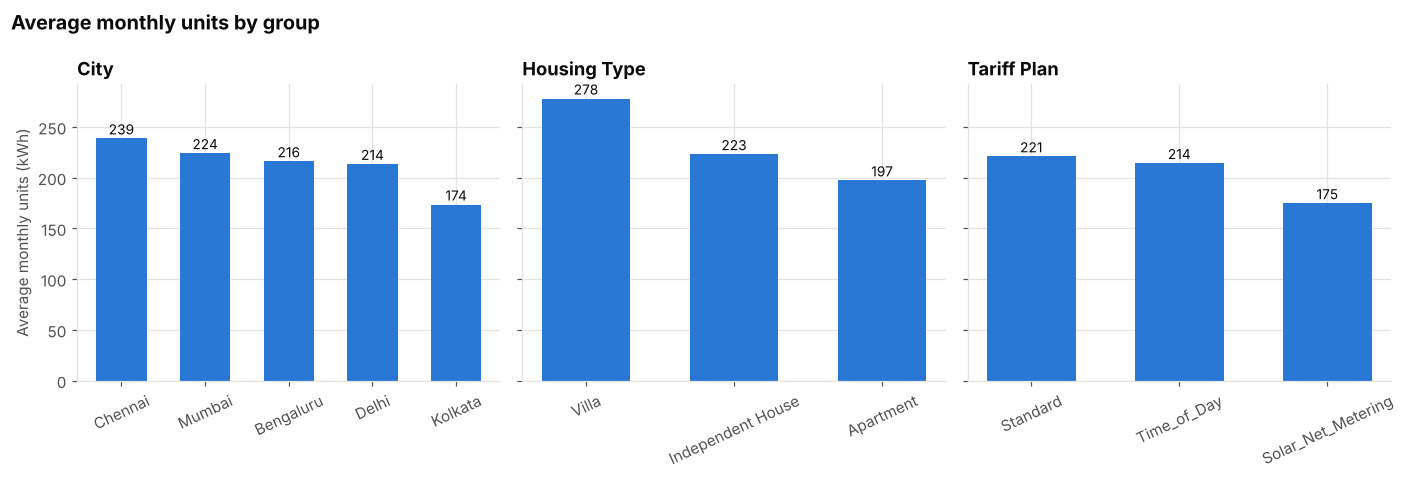

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, col in zip(axes, ["City", "Housing_Type", "Tariff_Plan"]):
    m = df.groupby(col)["Monthly_Units_kWh"].mean().sort_values(ascending=False)
    bars = ax.bar(m.index, m.values, color=BLUE, width=0.6)
    for b, v in zip(bars, m.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 4, f"{v:.0f}", ha="center", color=INK, fontsize=9)
    ax.set_title(col.replace("_", " "))
    ax.tick_params(axis="x", rotation=25)
    ax.set_xlabel("")
axes[0].set_ylabel("Average monthly units (kWh)")
fig.suptitle("Average monthly units by group", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../images/05_units_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

**What I see:** the groups differ. Solar net-metering homes use clearly fewer units than the others, which is expected because they generate part of their own power. Housing type also matters, and the city averages differ a little. Because the groups have different sizes, I treat the small differences with some care.

## 8. Question 4: Which households need attention?
A household is a **High Consumer** if it uses **more than 300 kWh in a month**.

In [18]:
hc = df[df["High_Consumer"] == "Yes"]
print("High Consumers:", len(hc), "out of", len(df), f"({len(hc)/len(df)*100:.1f}%)")
print()
print(df["Consumption_Level"].value_counts().reindex(["Low", "Medium", "High"]))
print()
print("Average of High Consumers vs the rest:")
df.groupby("High_Consumer")[["Home_Area_Sqft", "Num_Air_Conditioners", "Household_Size", "Monthly_Units_kWh"]].mean().round(1)

High Consumers: 34 out of 250 (13.6%)

Consumption_Level
Low        48
Medium    168
High       34
Name: count, dtype: int64

Average of High Consumers vs the rest:


,Home_Area_Sqft,Num_Air_Conditioners,Household_Size,Monthly_Units_kWh
High_Consumer,,,,
No,1125.0,1.4,3.7,194.8
Yes,1644.9,2.3,4.6,340.1


In [19]:
print("Share of High Consumers (%) by group")
for col in ["City", "Housing_Type", "Tariff_Plan"]:
    print((df.groupby(col)["High_Consumer"].apply(lambda s: (s == "Yes").mean() * 100)).round(1).sort_values(ascending=False).to_dict())

print()
print("Top 10 households by monthly units:")
df.sort_values("Monthly_Units_kWh", ascending=False).head(10)[
    ["Household_ID", "City", "Housing_Type", "Tariff_Plan", "Home_Area_Sqft",
     "Num_Air_Conditioners", "Monthly_Units_kWh", "Estimated_Bill_Rs"]]

Share of High Consumers (%) by group
{'Chennai': 25.0, 'Mumbai': 15.1, 'Bengaluru': 14.8, 'Kolkata': 8.8, 'Delhi': 8.2}
{'Villa': 41.4, 'Independent House': 13.2, 'Apartment': 8.3}
{'Time_of_Day': 14.3, 'Standard': 14.2, 'Solar_Net_Metering': 8.0}

Top 10 households by monthly units:


,Household_ID,City,Housing_Type,Tariff_Plan,Home_Area_Sqft,Num_Air_Conditioners,Monthly_Units_kWh,Estimated_Bill_Rs
128,E1072,Bengaluru,Villa,Standard,3000,3,444,3108
143,E1134,Bengaluru,Villa,Standard,2680,3,434,3038
211,E1223,Mumbai,Apartment,Standard,1260,2,398,2786
153,E1014,Delhi,Villa,Standard,1810,4,393,2751
148,E1144,Mumbai,Independent House,Standard,2260,2,381,2667
39,E1073,Bengaluru,Villa,Standard,2390,3,371,2597
167,E1173,Chennai,Independent House,Standard,1950,3,368,2576
187,E1046,Delhi,Villa,Standard,2550,4,359,2513
15,E1104,Delhi,Villa,Standard,1700,1,350,2450
152,E1115,Bengaluru,Villa,Time_of_Day,2080,1,346,2422


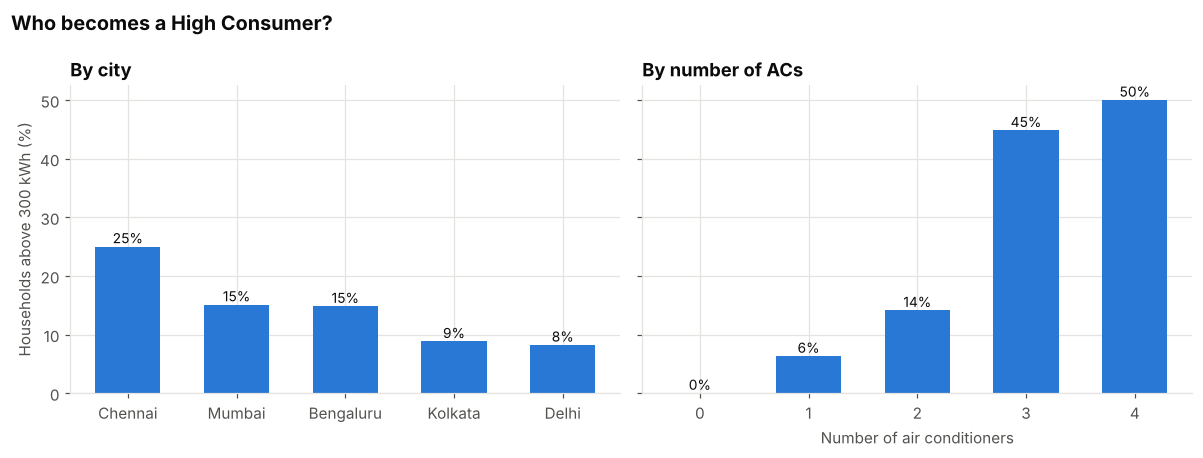

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

by_city = df.groupby("City")["High_Consumer"].apply(lambda s: (s == "Yes").mean() * 100).sort_values(ascending=False)
bars = axes[0].bar(by_city.index, by_city.values, color=BLUE, width=0.6)
for b, v in zip(bars, by_city.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.0f}%", ha="center", color=INK, fontsize=9)
axes[0].set_title("By city")
axes[0].set_ylabel("Households above 300 kWh (%)")

by_ac = df.groupby("Num_Air_Conditioners")["High_Consumer"].apply(lambda s: (s == "Yes").mean() * 100)
bars = axes[1].bar(by_ac.index.astype(str), by_ac.values, color=BLUE, width=0.6)
for b, v in zip(bars, by_ac.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v:.0f}%", ha="center", color=INK, fontsize=9)
axes[1].set_title("By number of ACs")
axes[1].set_xlabel("Number of air conditioners")

fig.suptitle("Who becomes a High Consumer?", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../images/06_high_consumers.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Key insights (numbers from my cleaned data of 250 households)
1. **Overall usage:** the average household uses **214.5 kWh** a month (median 215 kWh). Half of the households fall between **161 and 267 kWh**, and usage ranges from 40 to 444 kWh. The shape is close to symmetric (skewness 0.03).
2. **ACs are the strongest driver:** the correlation between `Num_Air_Conditioners` and units is **0.57**. Average usage rises from **146 kWh with no AC** to **187 (1 AC), 235 (2 ACs), 298 (3 ACs)** and **323 kWh with 4 ACs**, which is about 40 to 60 kWh more for each extra AC.
3. **Home size matters too:** the correlation between `Home_Area_Sqft` and units is **0.41**. Large homes (above 1500 sq ft) average **261 kWh**, against **185 kWh** for small homes (up to 800 sq ft).
4. **Weak or no effect:** `Household_Size` (0.15), `Avg_Temperature_C` (0.06) and `Meter_Age_Years` (0.08) have little relationship with units. Meter age is the clear "no effect" column.
5. **Groups differ:** villas average **278 kWh** against **197 kWh** for apartments. Solar net-metering homes average **175 kWh**, about 46 kWh below standard-tariff homes (**221 kWh**). By city, Chennai is highest (**239 kWh**) and Kolkata lowest (**174 kWh**).
6. **High Consumers (above 300 kWh):** **34 households (13.6%)**. They have larger homes (about 1645 sq ft against 1125) and more ACs (2.3 against 1.4 on average). Their estimated bill averages about Rs 2,381 against Rs 1,502 for all households.
7. **Where the risk is concentrated:** **41%** of villas are High Consumers (apartments 8%), and **45% of homes with 3 ACs** and 50% with 4 ACs are High Consumers (homes with no AC: 0%). By city, Chennai has the highest share (25%).

**Caution:** the data is synthetic and the groups are small in places (only 4 homes have 4 ACs, 25 are on solar), so the small differences should not be over-interpreted.

## 10. Recommendations for the manager
1. **Target AC-heavy homes first.** Homes with 3 or more ACs are the most likely to cross 300 kWh. Offer them BEE star-rated AC replacement discounts, smart-thermostat tips and a text alert when monthly usage passes about 250 kWh.
2. **Focus campaigns on villas and large homes.** About 4 in 10 villas are High Consumers, so energy audits and rooftop-solar offers will reach the most usage per household here.
3. **Promote solar net-metering.** These homes use about 46 kWh less than standard-tariff homes. Roll out simple subsidy and installation support, starting in the city and housing groups with the highest usage (Chennai, villas).
4. **Review tariffs for High Consumers.** Offer a time-of-day tariff or slab-based nudges to the 34 High Consumer households, since Time_of_Day homes currently use about the same as standard homes (214 vs 221 kWh) and the plan is not yet reducing usage much.
5. **Plan demand by city.** Use the city averages (Chennai about 239 kWh vs Kolkata about 174 kWh) and AC counts when forecasting load, instead of one average for everyone.
6. **Do not spend effort on meter age or household size for targeting.** They show little or no link with usage in this data.

## 11. Save the cleaned file

In [21]:
out = df.copy()
out["Billing_Date"] = out["Billing_Date"].dt.strftime("%Y-%m-%d")
out.to_csv("../data/processed/electricity_data_clean.csv", index=False)
print("Saved:", out.shape)

Saved: (250, 17)
